# Los 27 casos del estudio: el régimen en que cae cada uno y una repetición contra el motor vivo

**Pregunta:** ¿Qué regímenes de operación cubren los 27 casos horneados, dónde se niega el motor a dar un número confiado, y reproduce el motor vivo cada resultado horneado con la precisión que guardó el horneado?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook usted puede:

- leer el índice y los manifiestos de los casos versionados y ordenarlos como una matriz de máquina, etapa y punto de operación;
- correr el motor vivo sobre toda la matriz y leer el régimen, la validez y los códigos de aviso que entrega a cada caso;
- aplicar la compuerta de expectativas del pipeline a un resultado vivo, y explicar por qué un rango escrito a mano no es el valor del propio motor;
- repetir cada resultado horneado contra el motor vivo y decir qué tan grande puede ser una diferencia dada la precisión almacenada.

## Preparación

Este notebook usa las mismas dos bibliotecas que el primero. Los módulos del pipeline que importa son los ayudantes del manifiesto de casos (`core/manifest.py`, `core/trace.py`) y la compuerta de expectativas (`core/expect.py`), junto al motor.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La celda los importa e imprime las versiones de las bibliotecas.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import evaluate, Operating
from pipeline.core.manifest import flag_codes
from pipeline.core.trace import metrics_of
from pipeline.core.expect import check, ExpectationError
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El índice de los casos horneados y un manifiesto por caso, 28 archivos en total. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Los manifiestos del HP500 llevan los diez muestreos de Rocha et al. (2024), CC BY 4.0, https://doi.org/10.3390/min14090919, y lo declaran en su bloque `source`. Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json` de cada caso que lista el índice.

La celda siguiente lee el índice y luego cada manifiesto al que apunta, y los guarda en un diccionario por identificador de caso.

In [2]:
# Lea el índice y luego cada manifiesto que lista; un archivo ausente detiene el notebook con su ruta
derived = ROOT / "data" / "derived"
index = json.loads((derived / "manifests" / "index.json").read_text(encoding="utf-8"))
manifests = {c["case_id"]: json.loads((derived / c["manifest_path"]).read_text(encoding="utf-8")) for c in index["cases"]}
print("casos en el índice:", index["n_cases"], "| caso por defecto:", index["default_case"])

casos en el índice: 27 | caso por defecto: S01


## Método

**Paso 1, la matriz.** Cada manifiesto contiene el punto de operación (`params`), la etapa del circuito (primaria, secundaria, terciaria o control), si el caso es sintético o un muestreo real, y una etiqueta `control` para los tres casos que existen para probar las negativas del motor. Contar los casos por etapa y por máquina es la primera vista de lo que cubre el estudio: muestra si el cono secundario, el caballo de batalla del circuito, tiene más casos, y cuántos casos son datos reales.

In [3]:
# Cuente los casos por etapa y por máquina, y los reales
from collections import Counter

by_stage = Counter(m["stage"] for m in manifests.values())
by_machine = Counter(m["params"]["machine"] for m in manifests.values())
real = [k for k, m in manifests.items() if m["real_or_synthetic"] == "real"]
print("por etapa:", dict(by_stage))
print("por máquina:", dict(by_machine))
print("muestreos reales:", len(real), "| controles:", [k for k, m in manifests.items() if m["control"]])

por etapa: {'control': 3, 'primary': 4, 'tertiary': 4, 'secondary': 16}
por máquina: {'cone-sec': 19, 'gyratory': 2, 'cone-short-head': 2, 'jaw': 2, 'cone-tert': 2}
muestreos reales: 10 | controles: ['CI1', 'CK1', 'CP1']


**Paso 2, la corrida viva.** La celda corre el motor en cada punto de operación de la matriz, en el orden del índice. Dos cosas importan de cada resultado: si el motor llamó `valid` al punto, y qué códigos de aviso explican un rechazo. `flag_codes` convierte los textos de aviso del motor en los códigos estables que guarda el manifiesto. Aquí un caso se llama limpio cuando el motor no le da ningún aviso.

In [4]:
# Evalúe el motor vivo en cada caso y conserve resultado, régimen y avisos
live = {k: evaluate(Operating(**m["params"])) for k, m in manifests.items()}
flagged = {k: flag_codes(r) for k, r in live.items() if flag_codes(r)}
print("casos limpios:", len(live) - len(flagged), "de", len(live))
for k, codes in flagged.items():
    print(f"{k:9s} regime={live[k].regime:12s} valid={live[k].valid!s:5s} {codes}")

casos limpios: 23 de 27
CI1       regime=invalid      valid=False ['css_ge_feed_top', 'f80_lt_css']
CP1       regime=pass-through valid=False ['pass_through', 'f80_lt_css']
G02       regime=pass-through valid=False ['pass_through', 'f80_lt_css']
HP500-03  regime=pass-through valid=False ['pass_through', 'f80_lt_css']


Los cuatro casos con aviso no son defectos. Dos son los controles construidos para ser rechazados: CP1 fija una abertura de lado cerrado mayor que el F80 de la alimentación, de modo que casi todo el material no es tomado, y CI1 la fija mayor que el tamaño máximo de la alimentación, de modo que nada es tomado. Los otros dos, G02 y HP500-03, son casos comunes que están en el mismo borde: su F80 está en o bajo la abertura, y el motor lo dice en lugar de informar una reducción confiada. La figura ubica los 27 puntos por su tamaño de producto y su capacidad y marca los que tienen aviso.

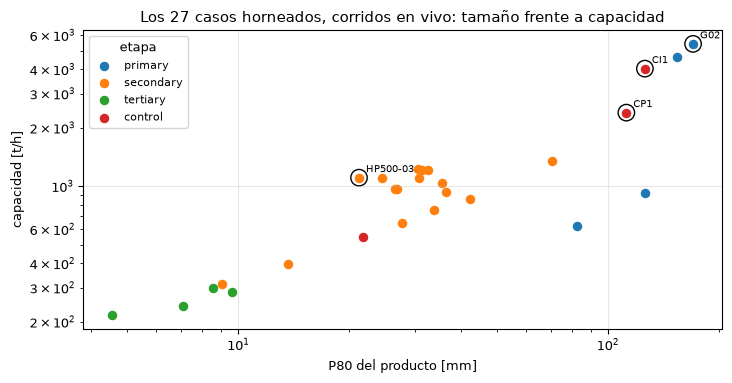

In [5]:
# Dispersión de los 27 resultados vivos por P80 del producto y capacidad, un color por etapa, casos con aviso encerrados
fig, ax = plt.subplots()
for stage in ("primary", "secondary", "tertiary", "control"):
    ids = [k for k, m in manifests.items() if m["stage"] == stage]
    ax.scatter([live[k].p80 for k in ids], [live[k].throughput_tph for k in ids], label=stage, s=34)
for k in flagged:
    ax.scatter([live[k].p80], [live[k].throughput_tph], s=140, facecolors="none", edgecolors="black")
    ax.annotate(k, (live[k].p80, live[k].throughput_tph), fontsize=7, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("P80 del producto [mm]")
ax.set_ylabel("capacidad [t/h]")
ax.set_title("Los 27 casos horneados, corridos en vivo: tamaño frente a capacidad")
ax.legend(title="etapa", fontsize=8)
fig.tight_layout()
plt.show()

La nube tiene la forma que debe tener un circuito de chancado: las máquinas que hacen los productos más finos (los conos terciarios y de cabeza corta, P80 bajo 10 mm) mueven unos cientos de toneladas por hora, los conos secundarios quedan al medio, y los chancadores giratorios y de mandíbulas de la etapa primaria entregan los productos más gruesos, de 82 a 170 mm, a 600 a 5400 t/h. Los círculos muestran que las negativas no son atípicos de la nube: un punto con aviso puede verse como cualquier otro, por eso el aviso, y no la posición, es lo que le dice al lector que desconfíe.

**Paso 3, las variantes.** El estudio permite al lector mover la abertura de lado cerrado 15 por ciento más cerrada o más abierta que el valor propio del caso. La celda corre cada uno de los 23 casos limpios con ambas aberturas y conserva la razón entre el resultado con la abertura ancha y el de la abertura angosta, para el P80 y para la capacidad. Las dos aberturas difieren en un factor 1,15 / 0,85 = 1,353, así que una razón cercana a 1,35 significaría que la magnitud sigue a la abertura uno a uno.

In [6]:
# Corra cada caso limpio con la abertura 15 % más cerrada y 15 % más abierta y compare los dos resultados
from dataclasses import replace

clean = [k for k in live if k not in flagged]
open_over_tight, leaves_valid = {}, []
for k in clean:
    op = Operating(**manifests[k]["params"])
    tight, wide = evaluate(replace(op, css_mm=op.css_mm * 0.85)), evaluate(replace(op, css_mm=op.css_mm * 1.15))
    open_over_tight[k] = (wide.p80 / tight.p80, wide.throughput_tph / tight.throughput_tph)
    if not wide.valid:
        leaves_valid.append((k, wide.regime))
p80_ratio = np.array([v[0] for v in open_over_tight.values()])
tph_ratio = np.array([v[1] for v in open_over_tight.values()])
print("razón de P80, ancha sobre angosta (mín, mediana, máx):", p80_ratio.min().round(3), np.median(p80_ratio).round(3), p80_ratio.max().round(3))
print("razón de capacidad (mín, mediana, máx):", tph_ratio.min().round(3), np.median(tph_ratio).round(3), tph_ratio.max().round(3))
print("producto más grueso con la abertura ancha:", int((p80_ratio > 1).sum()), "de", len(clean))
print("casos que salen del régimen válido con la abertura ancha:", leaves_valid)

razón de P80, ancha sobre angosta (mín, mediana, máx): 1.066 1.321 1.391
razón de capacidad (mín, mediana, máx): 1.149 1.24 1.319
producto más grueso con la abertura ancha: 23 de 23
casos que salen del régimen válido con la abertura ancha: [('G01', 'pass-through')]


En los 23 casos limpios la abertura más ancha da el producto más grueso. La razón mediana de P80 es 1,32, cercana a la proporcional 1,35, de modo que la abertura es la palanca principal sobre el tamaño del producto en todas las máquinas y etapas; la razón mediana de capacidad es 1,24, una respuesta más débil pero consistente. El único caso que sale del régimen válido muestra el borde de la palanca: G01, un giratorio, es un caso limpio con su propia abertura, pero con 15 por ciento más ancha cae al régimen de paso directo y el motor lo marca inválido. La celda siguiente traza la respuesta completa para el caso de referencia, desde la mitad hasta una vez y media su abertura.

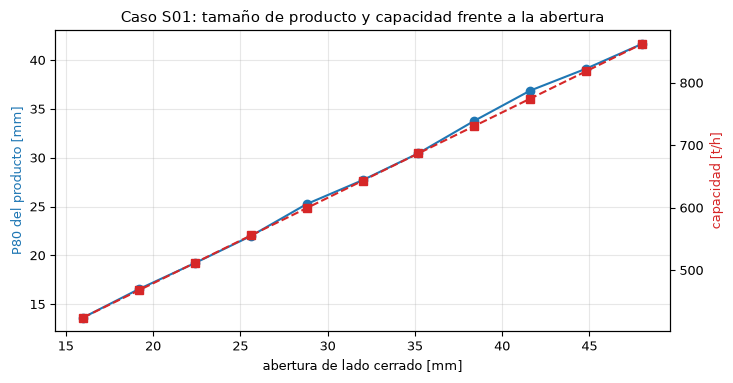

potencia con la abertura más cerrada y la más ancha [kW]: 341 251


In [7]:
# Barra la abertura de lado cerrado de S01 de 0,5 a 1,5 veces su valor y grafique P80 y capacidad
base = Operating(**manifests["S01"]["params"])
settings = base.css_mm * np.linspace(0.5, 1.5, 11)
runs = [evaluate(replace(base, css_mm=float(c))) for c in settings]
fig, ax = plt.subplots()
ax.plot(settings, [r.p80 for r in runs], "o-", color="tab:blue")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("P80 del producto [mm]", color="tab:blue")
twin = ax.twinx()
twin.plot(settings, [r.throughput_tph for r in runs], "s--", color="tab:red")
twin.set_ylabel("capacidad [t/h]", color="tab:red")
twin.grid(False)
ax.set_title("Caso S01: tamaño de producto y capacidad frente a la abertura")
fig.tight_layout()
plt.show()
print("potencia con la abertura más cerrada y la más ancha [kW]:", round(runs[0].power_kw), round(runs[-1].power_kw))

El P80 sube casi linealmente con la abertura, de 13,63 mm con 16 mm a 41,65 mm con 48 mm, y la capacidad sube de 424 a 862 t/h. Las curvas responden la pregunta de planta en una imagen: abrir el chancador da más toneladas y un producto más grueso, y la potencia, impresa bajo la figura, baja de 341 kW a 251 kW porque hay menos reducción de tamaño que pagar. La figura no muestra dónde el producto deja de cumplir el requisito de alimentación de la etapa siguiente; eso depende del circuito, que este producto no modela.

**Paso 4, la compuerta de expectativas.** Cada caso declara en su manifiesto el rango en que debe caer cada una de varias métricas del resultado, escrito a partir de relaciones de ingeniería o de mediciones y nunca del valor del propio motor (`core/expect.py`). El horneado falla con un valor fuera de su rango. La celda reutiliza la misma función, `check`, sobre el resultado vivo de cada caso: devuelve los rangos cuando todas las métricas están dentro y levanta `ExpectationError` nombrando las que no lo están.

In [8]:
# Aplique la compuerta de expectativas del pipeline a los resultados vivos; reúna lo que cae fuera de su rango
outside = {}
for k, m in manifests.items():
    try:
        check(k, {name: tuple(rng) for name, rng in m["expect"].items()}, metrics_of(live[k]))
    except ExpectationError as exc:
        outside[k] = str(exc)
print("casos dentro de cada rango escrito:", len(manifests) - len(outside), "de", len(manifests))
print("métricas con compuerta en S01:", sorted(manifests["S01"]["expect"]))

casos dentro de cada rango escrito: 27 de 27
métricas con compuerta en S01: ['p80_mm', 'reduction_ratio', 'throughput_tph']


**Paso 5, la repetición.** Los manifiestos guardan cada resultado redondeado a seis cifras significativas (`metrics`). El motor vivo trabaja en doble precisión, así que los dos no pueden ser idénticos, y la pregunta es cuánto pueden diferir sin que nada esté mal. Un número guardado con seis cifras significativas se equivoca como máximo en media unidad de su sexta cifra; relativo al número eso es a lo sumo 5e-6, y se alcanza cuando la primera cifra es 1. La celda calcula, para cada caso y cada métrica, la diferencia relativa entre el valor vivo y el almacenado y conserva la mayor por métrica.

In [9]:
# Repetición: el valor vivo sin redondear frente al almacenado, peor caso por métrica, y luego lo mismo tras el redondeo a seis cifras del pipeline
READOUTS = ("p80_mm", "p50_mm", "p20_mm", "f80_mm", "reduction_ratio", "throughput_tph", "power_kw", "specific_energy_kwh_t")
FIELD = {"p80_mm": "p80", "p50_mm": "p50", "p20_mm": "p20", "f80_mm": "f80"}
worst, exact, total = {}, 0, 0
for k, m in manifests.items():
    rounded = metrics_of(live[k])
    for name in READOUTS:
        raw = getattr(live[k], FIELD.get(name, name))
        rel = abs(raw - m["metrics"][name]) / max(abs(m["metrics"][name]), 1e-12)
        if rel > worst.get(name, (0.0, ""))[0]:
            worst[name] = (rel, k)
        total += 1
        exact += rounded[name] == m["metrics"][name]
for name, (rel, k) in worst.items():
    print(f"{name:24s} {rel:.2e}  ({k})")
print("la mayor de todas:", f"{max(r for r, _ in worst.values()):.2e}")
print("idénticos tras el redondeo a seis cifras:", exact, "de", total)

p80_mm                   3.53e-06  (J01)
p50_mm                   3.36e-06  (HP500-10)
p20_mm                   2.65e-06  (J01)
f80_mm                   2.97e-06  (CI1)
throughput_tph           4.56e-06  (HP500-08)
specific_energy_kwh_t    4.21e-06  (CI1)
reduction_ratio          3.72e-06  (CP1)
power_kw                 3.68e-06  (J02)
la mayor de todas: 4.56e-06
idénticos tras el redondeo a seis cifras: 216 de 216


La figura pone la peor diferencia de cada métrica frente a la cota de 5e-6 de la precisión almacenada. Una barra bajo la línea es una diferencia que el redondeo de las cifras guardadas explica por completo; una barra sobre ella sería una deriva del motor respecto de sus artefactos horneados, el hallazgo que la repetición existe para detectar.

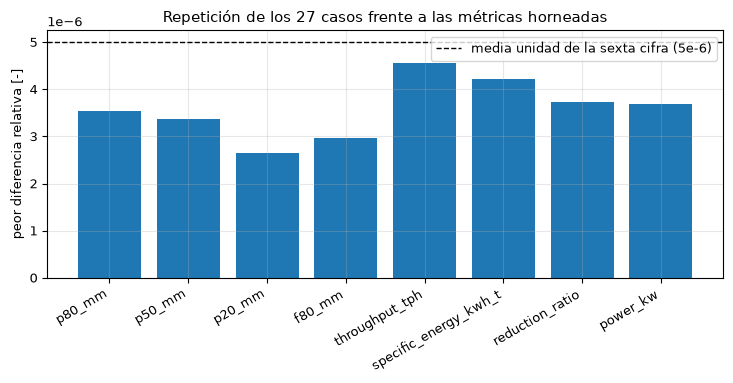

In [10]:
# Gráfico de barras de la peor diferencia de la repetición por métrica frente a la cota de redondeo de seis cifras significativas
names = list(worst)
fig, ax = plt.subplots()
ax.bar(range(len(names)), [worst[n][0] for n in names])
ax.axhline(5e-6, color="black", ls="--", lw=1, label="media unidad de la sexta cifra (5e-6)")
ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
ax.set_ylabel("peor diferencia relativa [-]")
ax.set_title("Repetición de los 27 casos frente a las métricas horneadas")
ax.legend()
fig.tight_layout()
plt.show()

Las ocho barras quedan bajo la línea, así que el motor vivo y los artefactos versionados coinciden hasta las cifras que se guardaron; ninguno de los 27 casos deriva. Esta es la única comprobación de reproducción del notebook, y no es la lección: la misma comparación corre en la batería de pruebas en cada cambio. Lo que la figura no puede decir es si alguno de los valores es correcto, porque ambos salen del mismo motor. Esa es la tarea de los oráculos del tema 02 y del tema 04, y de las mediciones del tema 05.

## Resultados

**Respuesta:** los 27 casos son 4 primarios, 16 secundarios (6 sintéticos y los 10 muestreos del HP500), 4 terciarios y 3 controles. El motor vivo llama limpios a 23 y marca 4: CI1 y CP1 (los controles), G02 y HP500-03, todos con el código `f80_lt_css`, una alimentación cuyo F80 está en o bajo la abertura de lado cerrado. Cada uno de los 27 resultados está dentro de su rango de expectativa escrito, y la repetición contra las métricas horneadas difiere a lo más en 4,56e-06 en términos relativos, bajo los 5e-6 que permiten seis cifras guardadas; tras el redondeo a seis cifras del propio pipeline los 216 valores (27 casos, 8 métricas) son idénticos a los almacenados.

De ahí salen dos lecturas. Primero, las negativas del motor son parte de su comportamiento y están cubiertas por casos: quien ajusta una máquina más ancha que su alimentación obtiene un aviso y un régimen de paso directo, no un tamaño de producto confiado. Segundo, que el motor vivo coincida con los números horneados establece que el pipeline es reproducible, no que el motor sea correcto: los 10 muestreos reales, donde una planta midió la capacidad, son la evidencia de eso, y son el tema del tema 05.

## Resumen

La matriz de casos es el mapa de cobertura del estudio: tres etapas, cinco máquinas, una vía real de diez muestreos y tres controles que existen para ser rechazados. Los ayudantes del manifiesto y la compuerta de expectativas son código compartido del pipeline, de modo que un notebook reutiliza lo que usa el horneado. Una repetición que coincide hasta las cifras guardadas prueba reproducibilidad; la corrección necesita una referencia independiente, que traen los temas siguientes. El tema 02 parte por la alimentación.

## Referencias

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919